# 4. Effect of Dimensionality

Notebook 03 showed that the KD-tree is slower than brute force on the full 384-dimensional embeddings. Here we test *why* by varying the number of dimensions $d$ and measuring both methods at each one.

**Method.** For each $d \in \{2, 4, 8, \dots, 256, 384\}$:

1. keep only the **first $d$ coordinates** of every database and query vector,
2. recompute the exact ground truth for that $d$ with brute force,
3. measure brute-force query time, KD-tree build time, KD-tree query time and KD-tree recall.

**Why truncate instead of using PCA?** We want a simple, controlled way to change only the dimension while keeping the same 50,000 points and the same queries. `all-MiniLM-L6-v2` is not trained to put the most important information in its first coordinates, so the truncated vectors are not good *semantic* embeddings. That does not matter here: each truncated dataset is treated as its own search problem with its own ground truth, and we only measure how the algorithms scale with $d$. PCA would be the natural alternative if search quality on the reduced vectors mattered.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial import KDTree
from scipy.spatial.distance import cdist
from evaluation import evaluate_search, measure_build_time
from tqdm.auto import tqdm

DATA_DIR = Path("wikipedia_nn_data")

X = np.load(DATA_DIR / "embeddings.npy")
Q = np.load(DATA_DIR / "queries.npy")

K = 10
REPEATS = 3

# Dimensions to test: powers of two up to the full 384
dimensions = [2, 4, 8, 16, 32, 64, 128, 256, 384]

## Brute-force search

In [2]:
# Same exact brute-force search as in notebook 02, repeated here so this
# notebook can run on its own.
def brute_force_search(X, q, k=10):

    distances = cdist(
        q.reshape(1, -1),
        X,
        metric="sqeuclidean"
    ).ravel()

    indices = np.argpartition(distances, k - 1)[:k]

    return indices[np.argsort(distances[indices])]

## Run the experiment

For every dimension we build a new KD-tree and measure both methods with `evaluate_search` (3 repeats, median time per query). This cell takes a few minutes.

In [3]:
dimension_results = []

for d in tqdm(dimensions, desc="Testing dimensions"):

    # Reduce dimensionality: keep only the first d coordinates.
    # ascontiguousarray copies the slice into contiguous memory for fast access.
    X_d = np.ascontiguousarray(X[:, :d])
    Q_d = np.ascontiguousarray(Q[:, :d])

    # Recompute ground truth: removing coordinates changes the nearest
    # neighbours, so every d needs its own exact reference answers
    G_d = np.array([
        brute_force_search(X_d, q, K)
        for q in Q_d
    ])

    # Evaluate brute force
    brute_results = evaluate_search(
        lambda q, k: brute_force_search(X_d, q, k),
        Q_d,
        G_d,
        k=K,
        repeats=REPEATS
    )

    # Build KDTree
    tree, build_time = measure_build_time(
        lambda: KDTree(X_d),
        repeats=REPEATS
    )

    # Evaluate KDTree
    kd_results = evaluate_search(
        lambda q, k: tree.query(q, k=k, eps=0, p=2)[1],
        Q_d,
        G_d,
        k=K,
        repeats=REPEATS
    )

    # Store results
    dimension_results.append({
        "dimension": d,
        "brute_time_ms": brute_results["query_time_ms"],
        "kd_time_ms": kd_results["query_time_ms"],
        "kd_recall": kd_results["recall"],
        "kd_build_time_s": build_time,
        "speedup": (
            brute_results["query_time_ms"]
            / kd_results["query_time_ms"]
        )
    })

    print(f"Completed dimension {d}")

Testing dimensions:   0%|          | 0/9 [00:00<?, ?it/s]

Completed dimension 2
Completed dimension 4
Completed dimension 8
Completed dimension 16
Completed dimension 32
Completed dimension 64
Completed dimension 128
Completed dimension 256
Completed dimension 384


## Results

In [4]:
# Collect the results in a table and save them.
df = pd.DataFrame(dimension_results)

df.to_csv(
    DATA_DIR / "dimensionality_results.csv",
    index=False
)

df

,dimension,brute_time_ms,kd_time_ms,kd_recall,kd_build_time_s,speedup
0,2,0.517194,0.014761,1.0,0.015157,35.038098
1,4,0.666821,0.016669,1.0,0.012485,40.004481
2,8,0.930557,0.073412,1.0,0.017041,12.675776
3,16,1.215608,0.776557,1.0,0.016565,1.565383
4,32,2.158664,2.884189,1.0,0.021797,0.748447
5,64,4.726339,10.116792,1.0,0.033414,0.467178
6,128,10.484507,17.004733,1.0,0.058486,0.616564
7,256,19.167535,32.292686,1.0,0.128745,0.593557
8,384,30.298494,36.037265,1.0,0.216047,0.840755


## Query time vs. dimension

Both axes are logarithmic.

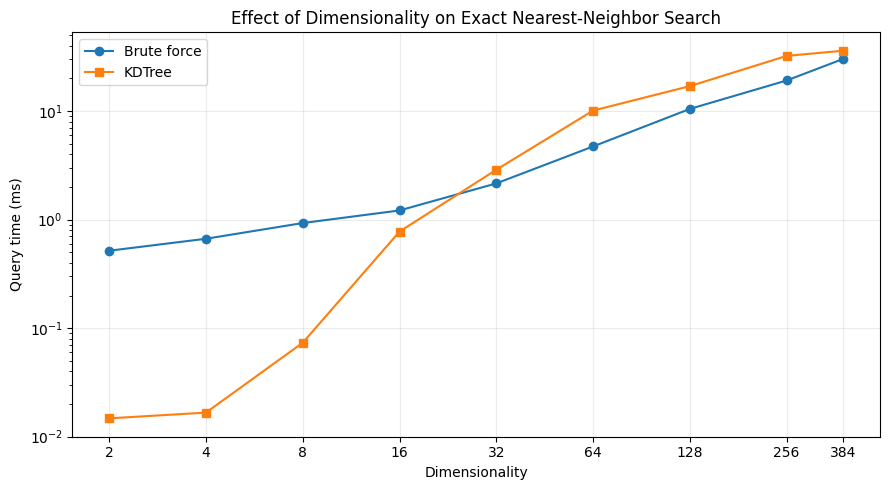

In [5]:
# Query time vs. dimension (log–log scale).
plt.figure(figsize=(9, 5))

plt.plot(
    df["dimension"],
    df["brute_time_ms"],
    "o-",
    label="Brute force"
)

plt.plot(
    df["dimension"],
    df["kd_time_ms"],
    "s-",
    label="KDTree"
)

plt.xscale("log", base=2)
plt.yscale("log")

plt.xticks(dimensions, dimensions)

plt.xlabel("Dimensionality")
plt.ylabel("Query time (ms)")
plt.title("Effect of Dimensionality on Exact Nearest-Neighbor Search")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## KD-tree speedup

Speedup = brute-force time / KD-tree time. Above the dashed line the KD-tree is faster; below it, brute force is faster.

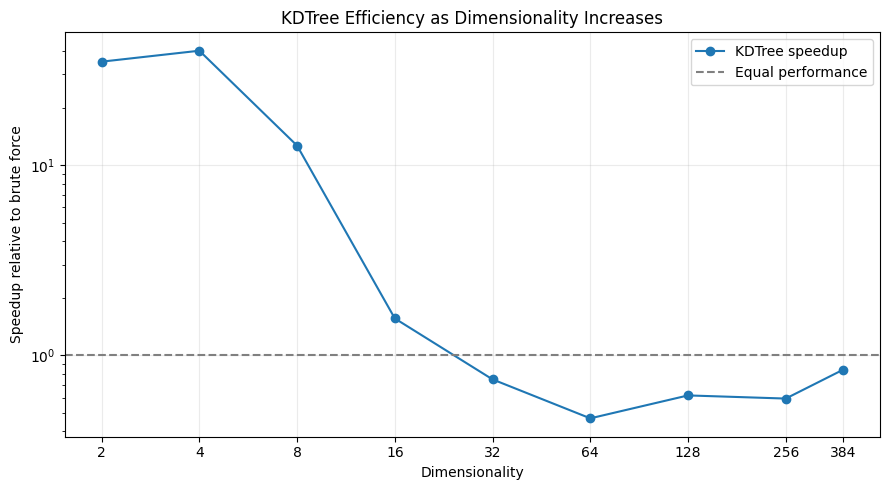

In [6]:
# Speedup of the KD-tree over brute force; the dashed line marks equal speed.
plt.figure(figsize=(9, 5))

plt.plot(
    df["dimension"],
    df["speedup"],
    "o-",
    label="KDTree speedup"
)

plt.axhline(
    y=1,
    linestyle="--",
    color="gray",
    label="Equal performance"
)

plt.xscale("log", base=2)
plt.yscale("log")
plt.xticks(dimensions, dimensions)

plt.xlabel("Dimensionality")
plt.ylabel("Speedup relative to brute force")
plt.title("KDTree Efficiency as Dimensionality Increases")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Conclusions

* **Low dimensions: the KD-tree wins clearly.** At $d = 2$–$4$ it is about **35–40× faster** than brute force, and still **12.7×** faster at $d = 8$.
* **The advantage disappears quickly.** At $d = 16$ the speedup is only 1.6×, and from **$d = 32$ upwards the KD-tree is slower** than brute force (0.47–0.84×).
* **Brute force scales smoothly.** Its query time grows roughly linearly with $d$ (0.5 ms → 30 ms), as expected from its $O(n \cdot d)$ cost.
* **The KD-tree's query time grows much faster**, from 0.015 ms at $d = 2$ to 36 ms at $d = 384$, because pruning stops working and the search visits most of the tree.
* **Recall is 1.0 at every dimension**, so the KD-tree stays exact; only its speed suffers.
* **Build time stays small** (at most 0.22 s), so construction is not the problem.

The break-even point matches a common rule of thumb: KD-trees are only efficient when $n \gg 2^d$. With $n = 50{,}000 \approx 2^{15.6}$, the tree should stop helping at around $d \approx 16$, which is exactly where our measured speedup drops to about 1.

**Takeaway:** for high-dimensional data such as sentence embeddings, exact space-partitioning trees give no benefit over brute force. Faster search in this setting requires approximate methods that trade a little recall for speed.